# Analisis Churn Nasabah Bank: Siapa yang Paling Berisiko Pergi?

## Latar Belakang
Analisis ini mencari faktor yang memengaruhi churn pada data
10.000 nasabah bank (Bank Customer Churn Records, Kaggle).
Churn rate keseluruhan sekitar 20%, sehingga bank perlu tahu
segmen mana yang paling berisiko agar program retensi tepat sasaran.

## Pertanyaan Bisnis
1. Berapa churn rate keseluruhan, dan di negara/gender mana paling tinggi?
2. Kelompok usia mana yang paling berisiko churn?
3. Bagaimana pengaruh jumlah produk dan keaktifan nasabah?
4. Apakah nasabah bersaldo besar lebih rentan pergi?
5. Apa peran komplain dan skor kepuasan terhadap churn?

## Tools
Python (pandas, matplotlib), Google Colab

## 1. Ambil Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Customer-Churn-Records.csv")

print("Ukuran data (baris, kolom):", df.shape)

Saving Customer-Churn-Records.csv to Customer-Churn-Records (4).csv
Ukuran data (baris, kolom): (10000, 18)


In [2]:
display(df.head())
df.info()
display(df.describe())
display(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


## 2. Cleaning Data

In [3]:
print("Duplikat baris      :", df.duplicated().sum())
print("Duplikat CustomerId :", df["CustomerId"].duplicated().sum())

print("\nCreditScore 300-850 :", df["CreditScore"].between(300, 850).all())
print("Age 18-100          :", df["Age"].between(18, 100).all())
print("Balance >= 0        :", (df["Balance"] >= 0).all())
print("Exited hanya 0/1    :", df["Exited"].isin([0, 1]).all())

df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

df = df.rename(columns={
    "CreditScore": "credit_score",
    "Geography": "geography",
    "Gender": "gender",
    "Age": "age",
    "Tenure": "tenure",
    "Balance": "balance",
    "NumOfProducts": "num_of_products",
    "HasCrCard": "has_cr_card",
    "IsActiveMember": "is_active_member",
    "EstimatedSalary": "estimated_salary",
    "Exited": "exited",
    "Complain": "complain",
    "Satisfaction Score": "satisfaction_score",
    "Card Type": "card_type",
    "Point Earned": "point_earned",
})

print("\nUkuran data:", df.shape)
print(list(df.columns))

Duplikat baris      : 0
Duplikat CustomerId : 0

CreditScore 300-850 : True
Age 18-100          : True
Balance >= 0        : True
Exited hanya 0/1    : True

Ukuran data: (10000, 15)
['credit_score', 'geography', 'gender', 'age', 'tenure', 'balance', 'num_of_products', 'has_cr_card', 'is_active_member', 'estimated_salary', 'exited', 'complain', 'satisfaction_score', 'card_type', 'point_earned']


In [4]:
df["age_group"] = pd.cut(
    df["age"], bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
)

df["credit_band"] = pd.cut(
    df["credit_score"], bins=[299, 579, 669, 739, 799, 850],
    labels=["Poor", "Fair", "Good", "Very Good", "Exceptional"]
)

df["products_group"] = pd.cut(
    df["num_of_products"], bins=[0, 1, 2, 4],
    labels=["1 produk", "2 produk", "3+ produk"]
)

punya_saldo = df["balance"] > 0
df["balance_group"] = "Zero balance"
df.loc[punya_saldo, "balance_group"] = pd.qcut(
    df.loc[punya_saldo, "balance"], q=4,
    labels=["Q1 Rendah", "Q2", "Q3", "Q4 Tinggi"]
).astype(str)

median_saldo = df.loc[punya_saldo, "balance"].median()
df["high_value_inactive"] = (
    (df["balance"] >= median_saldo) & (df["is_active_member"] == 0)
).astype(int)

print("Ukuran data:", df.shape)
for kolom in ["age_group", "credit_band", "products_group",
              "balance_group", "high_value_inactive"]:
    print("\n" + kolom)
    print(df[kolom].value_counts().sort_index())

Ukuran data: (10000, 20)

age_group
age_group
18-29    1641
30-39    4346
40-49    2618
50-59     869
60+       526
Name: count, dtype: int64

credit_band
credit_band
Poor           2362
Fair           3331
Good           2428
Very Good      1224
Exceptional     655
Name: count, dtype: int64

products_group
products_group
1 produk     5084
2 produk     4590
3+ produk     326
Name: count, dtype: int64

balance_group
balance_group
Q1 Rendah       1596
Q2              1596
Q3              1595
Q4 Tinggi       1596
Zero balance    3617
Name: count, dtype: int64

high_value_inactive
high_value_inactive
0    8431
1    1569
Name: count, dtype: int64


## 3. Mulai Analisis (EDA)

In [5]:
total = len(df)
churn = df["exited"].sum()
bertahan = total - churn

print("Total nasabah  :", total)
print("Nasabah churn  :", churn)
print("Nasabah bertahan:", bertahan)
print("Churn rate     :", round(churn / total * 100, 2), "%")

print(df["exited"].value_counts())

Total nasabah  : 10000
Nasabah churn  : 2038
Nasabah bertahan: 7962
Churn rate     : 20.38 %
exited
0    7962
1    2038
Name: count, dtype: int64


**Temuan:**
- Dari 10.000 nasabah, 2.038 churn dan 7.962 bertahan.
- Churn rate keseluruhan 20,38%, artinya sekitar 1 dari 5 nasabah pergi.

In [6]:
negara = df.groupby("geography").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
negara["Churn_Rate"] = (negara["Churn_Rate"] * 100).round(2)
print(negara.sort_values("Churn_Rate", ascending=False))

gender = df.groupby("gender").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
gender["Churn_Rate"] = (gender["Churn_Rate"] * 100).round(2)
print(gender.sort_values("Churn_Rate", ascending=False))

           Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
geography                                          
Germany              2509           814       32.44
Spain                2477           413       16.67
France               5014           811       16.17
        Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
gender                                          
Female            4543          1139       25.07
Male              5457           899       16.47


**Temuan:**
- Germany punya churn rate tertinggi (32,44%), hampir dua kali lipat
  France (16,15%) dan Spain (16,67%).
- Jumlah nasabah churn di Germany (814) hampir sama dengan France (811),
  padahal nasabah France dua kali lebih banyak.
- Nasabah perempuan lebih sering churn (25,07%) dibanding laki-laki (16,47%).

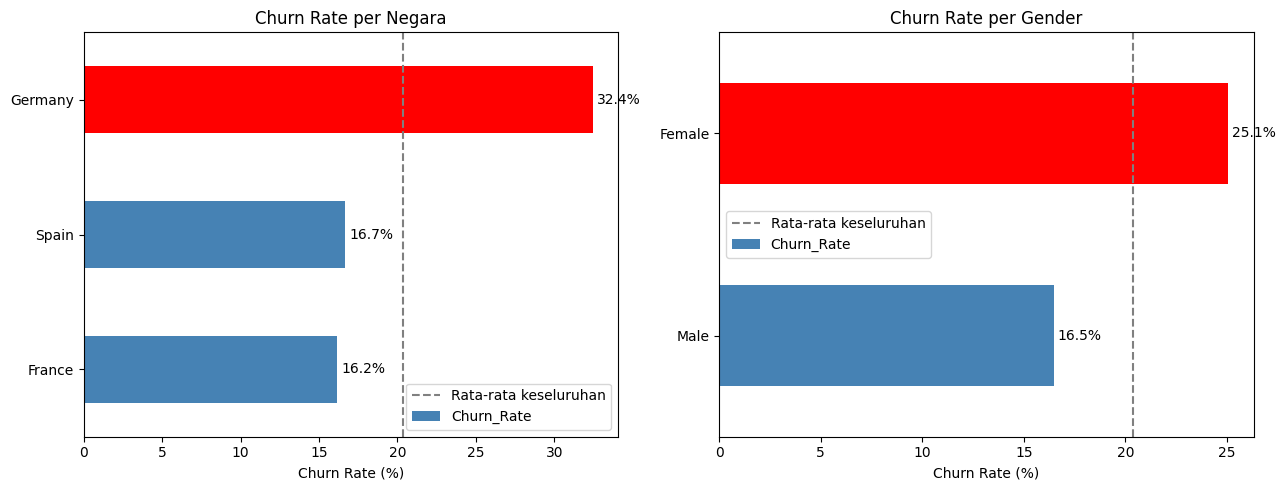

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
rata_rata = df["exited"].mean() * 100

n = negara["Churn_Rate"].sort_values()
warna_n = ["red" if x == n.max() else "steelblue" for x in n]
n.plot(kind="barh", ax=ax[0], color=warna_n)
ax[0].axvline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_title("Churn Rate per Negara")
ax[0].set_xlabel("Churn Rate (%)")
ax[0].set_ylabel("")
ax[0].legend()

g = gender["Churn_Rate"].sort_values()
warna_g = ["red" if x == g.max() else "steelblue" for x in g]
g.plot(kind="barh", ax=ax[1], color=warna_g)
ax[1].axvline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3)
ax[1].set_title("Churn Rate per Gender")
ax[1].set_xlabel("Churn Rate (%)")
ax[1].set_ylabel("")
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Germany (32,4%) dan nasabah perempuan (25,1%) berada di atas
rata-rata churn keseluruhan (20,4%), sedangkan France, Spain, dan
nasabah laki-laki berada di bawahnya.

## 4. Investigasi Usia

In [8]:
usia = df.groupby("age_group", observed=True).agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
usia["Churn_Rate"] = (usia["Churn_Rate"] * 100).round(2)
usia["Porsi_dari_Total_Churn_%"] = (usia["Jumlah_Churn"] / usia["Jumlah_Churn"].sum() * 100).round(1)
print(usia)

rata_usia = df.groupby("exited")["age"].agg(["mean", "median"]).round(2)
rata_usia.index = ["Bertahan", "Churn"]
print(rata_usia)

           Jumlah_Nasabah  Jumlah_Churn  Churn_Rate  Porsi_dari_Total_Churn_%
age_group                                                                    
18-29                1641           124        7.56                       6.1
30-39                4346           473       10.88                      23.2
40-49                2618           807       30.83                      39.6
50-59                 869           487       56.04                      23.9
60+                   526           147       27.95                       7.2
           mean  median
Bertahan  37.41    36.0
Churn     44.84    45.0


**Temuan:**
- Churn rate naik tajam seiring usia: 7,56% (18-29), 10,88% (30-39),
  30,83% (40-49), dan puncaknya 56,04% pada usia 50-59.
- Kelompok 60+ turun ke 27,95%, jadi risiko tertinggi ada di usia 40-59.
- Kelompok 40-49 menyumbang porsi churn terbesar (39,6%) karena jumlah
  nasabahnya banyak, sedangkan 50-59 punya risiko tertinggi per nasabah.
- Nasabah yang churn rata-rata 44,8 tahun, sekitar 7 tahun lebih tua
  dari yang bertahan (37,4 tahun).

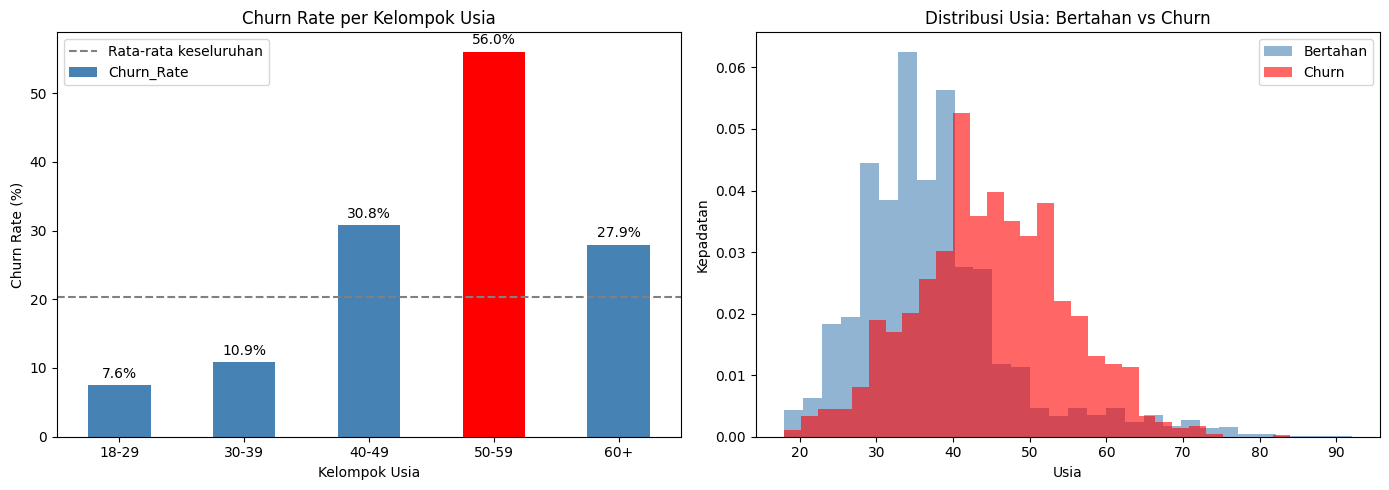

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rata_rata = df["exited"].mean() * 100

u = usia["Churn_Rate"]
warna_u = ["red" if x == u.max() else "steelblue" for x in u]
u.plot(kind="bar", ax=ax[0], color=warna_u, rot=0)
ax[0].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_title("Churn Rate per Kelompok Usia")
ax[0].set_xlabel("Kelompok Usia")
ax[0].set_ylabel("Churn Rate (%)")
ax[0].legend()

df[df["exited"] == 0]["age"].plot(kind="hist", bins=30, alpha=0.6, density=True,
                                  ax=ax[1], color="steelblue", label="Bertahan")
df[df["exited"] == 1]["age"].plot(kind="hist", bins=30, alpha=0.6, density=True,
                                  ax=ax[1], color="red", label="Churn")
ax[1].set_title("Distribusi Usia: Bertahan vs Churn")
ax[1].set_xlabel("Usia")
ax[1].set_ylabel("Kepadatan")
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Nasabah yang bertahan terkonsentrasi di usia 30-an, sedangkan
nasabah yang churn bergeser ke usia 40-50-an. Pola ini konsisten dengan
tabel: risiko churn meningkat tajam setelah usia 40 dan mencapai puncak
di usia 50-59.

## 5. Jumlah Produk dan Keaktifan Nasabah

In [10]:
produk = df.groupby("num_of_products").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
produk["Churn_Rate"] = (produk["Churn_Rate"] * 100).round(2)
print(produk)

aktif = df.groupby("is_active_member").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
aktif["Churn_Rate"] = (aktif["Churn_Rate"] * 100).round(2)
aktif.index = ["Tidak aktif", "Aktif"]
print(aktif)

silang = df.pivot_table(
    index="products_group",
    columns="is_active_member",
    values="exited",
    aggfunc="mean",
    observed=False
) * 100
silang.columns = ["Tidak aktif", "Aktif"]
print(silang.round(2))

                 Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
num_of_products                                          
1                          5084          1409       27.71
2                          4590           349        7.60
3                           266           220       82.71
4                            60            60      100.00
             Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
Tidak aktif            4849          1303       26.87
Aktif                  5151           735       14.27
                Tidak aktif  Aktif
products_group                    
1 produk              36.65  18.92
2 produk               9.93   5.56
3+ produk             90.22  80.28


**Temuan:**
- Nasabah dengan 2 produk paling loyal (churn 7,60%), jauh di bawah
  nasabah 1 produk (27,71%).
- Churn melonjak pada 3 produk (82,71%) dan 4 produk (100%), meski
  jumlahnya kecil (326 nasabah), sehingga perlu diselidiki lebih lanjut.
- Nasabah tidak aktif churn 26,87%, hampir dua kali lipat nasabah aktif
  (14,27%).
- Keaktifan menurunkan risiko churn di semua kelompok produk, paling
  besar pada nasabah 1 produk (36,65% menjadi 18,92%).

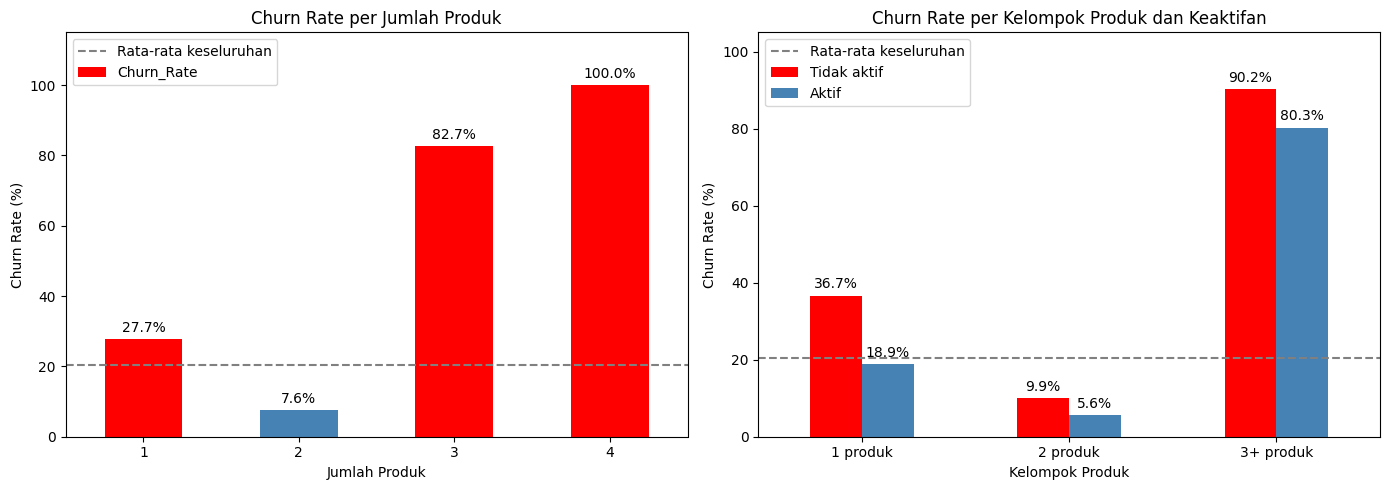

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rata_rata = df["exited"].mean() * 100

p = produk["Churn_Rate"]
warna_p = ["red" if x > rata_rata else "steelblue" for x in p]
p.plot(kind="bar", ax=ax[0], color=warna_p, rot=0)
ax[0].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_title("Churn Rate per Jumlah Produk")
ax[0].set_xlabel("Jumlah Produk")
ax[0].set_ylabel("Churn Rate (%)")
ax[0].set_ylim(0, 115)
ax[0].legend()

silang.plot(kind="bar", ax=ax[1], color=["red", "steelblue"], rot=0)
ax[1].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
for wadah in ax[1].containers:
    ax[1].bar_label(wadah, fmt="%.1f%%", padding=3)
ax[1].set_title("Churn Rate per Kelompok Produk dan Keaktifan")
ax[1].set_xlabel("Kelompok Produk")
ax[1].set_ylabel("Churn Rate (%)")
ax[1].set_ylim(0, 105)
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Hubungan jumlah produk dengan churn berbentuk huruf U:
terendah di 2 produk (7,6%), lebih tinggi di 1 produk (27,7%), dan sangat
tinggi di 3-4 produk (82,7% dan 100%). Di setiap kelompok produk, nasabah
tidak aktif selalu lebih sering churn daripada nasabah aktif, sehingga
keaktifan menjadi sinyal risiko yang konsisten.

## 6. Saldo Nasabah dan Nasabah Bernilai Tinggi

In [12]:
saldo = df.groupby("balance_group").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean"),
    Rata_Saldo=("balance", "mean")
)
saldo["Churn_Rate"] = (saldo["Churn_Rate"] * 100).round(2)
saldo["Rata_Saldo"] = saldo["Rata_Saldo"].round(2)
saldo = saldo.reindex(["Zero balance", "Q1 Rendah", "Q2", "Q3", "Q4 Tinggi"])
print(saldo)

prioritas = df.groupby("high_value_inactive").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
prioritas["Churn_Rate"] = (prioritas["Churn_Rate"] * 100).round(2)
prioritas["Porsi_dari_Total_Churn_%"] = (prioritas["Jumlah_Churn"] / prioritas["Jumlah_Churn"].sum() * 100).round(1)
prioritas.index = ["Lainnya", "Saldo tinggi & tidak aktif"]
print(prioritas)

rata_saldo = df.groupby("exited")["balance"].agg(["mean", "median"]).round(2)
rata_saldo.index = ["Bertahan", "Churn"]
print(rata_saldo)

total_saldo = df["balance"].sum()
saldo_churn = df.loc[df["exited"] == 1, "balance"].sum()
print("Total saldo semua nasabah :", round(total_saldo))
print("Saldo milik nasabah churn :", round(saldo_churn))
print("Persentase saldo churn    :", round(saldo_churn / total_saldo * 100, 2), "%")

               Jumlah_Nasabah  Jumlah_Churn  Churn_Rate  Rata_Saldo
balance_group                                                      
Zero balance             3617           500       13.82        0.00
Q1 Rendah                1596           330       20.68    81901.67
Q2                       1596           437       27.38   110269.28
Q3                       1595           404       25.33   129148.73
Q4 Tinggi                1596           367       22.99   157996.13
                            Jumlah_Nasabah  Jumlah_Churn  Churn_Rate  \
Lainnya                               8431          1548       18.36   
Saldo tinggi & tidak aktif            1569           490       31.23   

                            Porsi_dari_Total_Churn_%  
Lainnya                                         76.0  
Saldo tinggi & tidak aktif                      24.0  
              mean     median
Bertahan  72742.75   92063.06
Churn     91109.48  109344.23
Total saldo semua nasabah : 764858893
Saldo milik na

**Temuan:**
- Nasabah bersaldo nol paling jarang churn (13,82%); nasabah bersaldo
  churn di kisaran 20,68% sampai 27,38% tanpa pola yang jelas naik
  mengikuti besar saldo.
- Nasabah yang churn punya saldo lebih tinggi (median 109.344) daripada
  yang bertahan (median 92.063).
- Nasabah bersaldo tinggi yang tidak aktif (1.569 orang) churn 31,23%,
  dibanding 18,36% untuk nasabah lainnya. Kelompok ini hanya 15,7%
  dari nasabah tetapi menyumbang 24,0% dari seluruh churn.
- Saldo milik nasabah churn mencapai 24,28% dari total saldo seluruh
  nasabah, sehingga dampak finansialnya lebih besar daripada persentase
  jumlah nasabahnya.

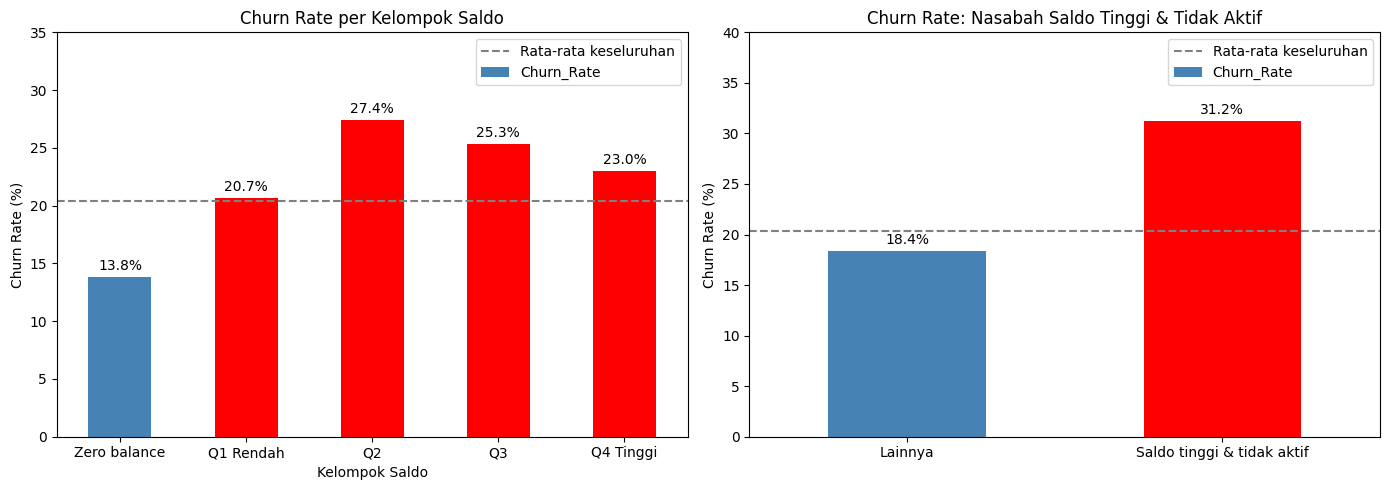

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rata_rata = df["exited"].mean() * 100

s = saldo["Churn_Rate"]
warna_s = ["red" if x > rata_rata else "steelblue" for x in s]
s.plot(kind="bar", ax=ax[0], color=warna_s, rot=0)
ax[0].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%", padding=3)
ax[0].set_title("Churn Rate per Kelompok Saldo")
ax[0].set_xlabel("Kelompok Saldo")
ax[0].set_ylabel("Churn Rate (%)")
ax[0].set_ylim(0, 35)
ax[0].legend()

pr = prioritas["Churn_Rate"]
warna_pr = ["red" if x > rata_rata else "steelblue" for x in pr]
pr.plot(kind="bar", ax=ax[1], color=warna_pr, rot=0)
ax[1].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3)
ax[1].set_title("Churn Rate: Nasabah Saldo Tinggi & Tidak Aktif")
ax[1].set_xlabel("")
ax[1].set_ylabel("Churn Rate (%)")
ax[1].set_ylim(0, 40)
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Churn rate tidak naik rapi mengikuti besar saldo: nasabah
bersaldo nol paling rendah (13,8%), sedangkan kelompok bersaldo berada
di 20,7% sampai 27,4%. Perbedaan yang lebih jelas terlihat pada
keaktifan: nasabah bersaldo tinggi yang tidak aktif churn 31,2%,
jauh di atas nasabah lainnya (18,4%).

## 7. Komplain dan Skor Kepuasan

In [14]:
komplain = df.groupby("complain").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
komplain["Churn_Rate"] = (komplain["Churn_Rate"] * 100).round(2)
komplain.index = ["Tidak komplain", "Komplain"]
print(komplain)

print(pd.crosstab(
    df["complain"].map({0: "Tidak komplain", 1: "Komplain"}),
    df["exited"].map({0: "Bertahan", 1: "Churn"})
))

kepuasan = df.groupby("satisfaction_score").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
kepuasan["Churn_Rate"] = (kepuasan["Churn_Rate"] * 100).round(2)
print(kepuasan)

kartu = df.groupby("card_type").agg(
    Jumlah_Nasabah=("exited", "count"),
    Jumlah_Churn=("exited", "sum"),
    Churn_Rate=("exited", "mean")
)
kartu["Churn_Rate"] = (kartu["Churn_Rate"] * 100).round(2)
print(kartu.sort_values("Churn_Rate", ascending=False))

print(df[["complain", "satisfaction_score", "exited"]].corr().round(3)["exited"])

                Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
Tidak komplain            7956             4        0.05
Komplain                  2044          2034       99.51
exited          Bertahan  Churn
complain                       
Komplain              10   2034
Tidak komplain      7952      4
                    Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
satisfaction_score                                          
1                             1932           387       20.03
2                             2014           439       21.80
3                             2042           401       19.64
4                             2008           414       20.62
5                             2004           397       19.81
           Jumlah_Nasabah  Jumlah_Churn  Churn_Rate
card_type                                          
DIAMOND              2507           546       21.78
PLATINUM             2495           508       20.36
SILVER               2496           502       20.11
GOLD          

**Temuan:**
- Dari 2.044 nasabah yang komplain, 2.034 churn (99,51%), sedangkan
  dari 7.956 nasabah yang tidak komplain hanya 4 yang churn (0,05%).
  Korelasi komplain dengan churn mencapai 0,996.
- Hubungan sekuat ini tidak wajar, dan kemungkinan besar kolom komplain
  dicatat setelah nasabah memutuskan pergi (data leakage). Karena itu
  komplain tidak dipakai sebagai faktor penjelas penyebab churn.
- Skor kepuasan tidak berhubungan dengan churn: churn rate hampir sama
  di semua skor (19,64% sampai 21,80%) dengan korelasi -0,006.
- Jenis kartu juga bukan pembeda yang kuat (19,26% sampai 21,78%).

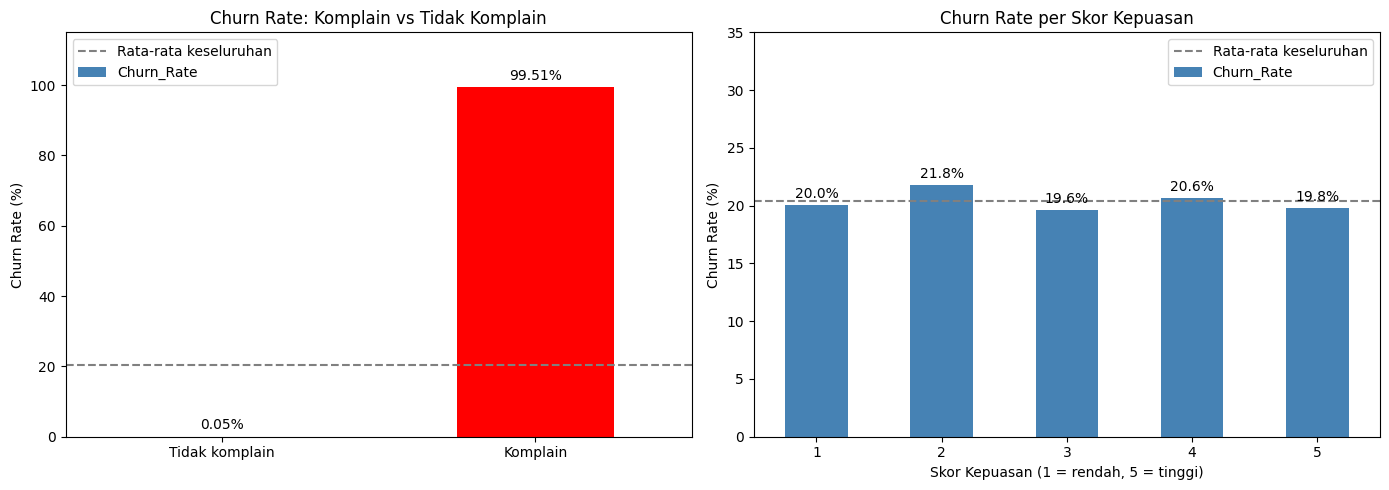

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rata_rata = df["exited"].mean() * 100

k = komplain["Churn_Rate"]
warna_k = ["red" if x > rata_rata else "steelblue" for x in k]
k.plot(kind="bar", ax=ax[0], color=warna_k, rot=0)
ax[0].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f%%", padding=3)
ax[0].set_title("Churn Rate: Komplain vs Tidak Komplain")
ax[0].set_xlabel("")
ax[0].set_ylabel("Churn Rate (%)")
ax[0].set_ylim(0, 115)
ax[0].legend()

kp = kepuasan["Churn_Rate"]
kp.plot(kind="bar", ax=ax[1], color="steelblue", rot=0)
ax[1].axhline(rata_rata, color="gray", linestyle="--", label="Rata-rata keseluruhan")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3)
ax[1].set_title("Churn Rate per Skor Kepuasan")
ax[1].set_xlabel("Skor Kepuasan (1 = rendah, 5 = tinggi)")
ax[1].set_ylabel("Churn Rate (%)")
ax[1].set_ylim(0, 35)
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Komplain memisahkan churn secara hampir sempurna (99,51%
dibanding 0,05%), sedangkan skor kepuasan tidak memisahkan apa pun:
semua skor berada di sekitar rata-rata 20%. Skor kepuasan saat ini
tidak berguna untuk memprediksi churn, sehingga cara pengukurannya
perlu dievaluasi.

## 8. Validasi: Mengapa Germany Lebih Tinggi?

In [16]:
profil = df.groupby("geography").agg(
    Jumlah_Nasabah=("exited", "count"),
    Churn_Rate=("exited", "mean"),
    Rata_Usia=("age", "mean"),
    Persen_Aktif=("is_active_member", "mean"),
    Persen_Perempuan=("gender", lambda x: (x == "Female").mean()),
    Rata_Produk=("num_of_products", "mean"),
    Persen_Saldo_Nol=("balance", lambda x: (x == 0).mean()),
    Rata_Saldo=("balance", "mean"),
    Rata_Gaji=("estimated_salary", "mean")
)
for kolom in ["Churn_Rate", "Persen_Aktif", "Persen_Perempuan", "Persen_Saldo_Nol"]:
    profil[kolom] = profil[kolom] * 100
print(profil.round(2).T)

df_saldo = df[df["balance"] > 0]
saldo_pos = df_saldo.groupby("geography").agg(
    Jumlah_Nasabah=("exited", "count"),
    Churn_Rate=("exited", "mean")
)
saldo_pos["Churn_Rate"] = (saldo_pos["Churn_Rate"] * 100).round(2)
print(saldo_pos)

usia_negara = df.pivot_table(
    index="age_group", columns="geography", values="exited",
    aggfunc="mean", observed=False
) * 100
print(usia_negara.round(2))

for kolom in ["gender", "is_active_member", "products_group"]:
    tabel = df.pivot_table(
        index=kolom, columns="geography", values="exited",
        aggfunc="mean", observed=False
    ) * 100
    print(tabel.round(2))

geography           France    Germany     Spain
Jumlah_Nasabah     5014.00    2509.00   2477.00
Churn_Rate           16.17      32.44     16.67
Rata_Usia            38.51      39.77     38.89
Persen_Aktif         51.68      49.74     52.97
Persen_Perempuan     45.09      47.55     43.96
Rata_Produk           1.53       1.52      1.54
Persen_Saldo_Nol     48.22       0.00     48.41
Rata_Saldo        62092.64  119730.12  61818.15
Rata_Gaji         99899.18  101113.44  99440.57
           Jumlah_Nasabah  Churn_Rate
geography                            
France               2596       18.26
Germany              2509       32.44
Spain                1278       19.56
geography  France  Germany  Spain
age_group                        
18-29        5.20    12.63   7.94
30-39        8.13    18.86   9.28
40-49       25.60    45.14  24.37
50-59       51.57    70.04  45.71
60+         24.82    41.46  21.71
geography  France  Germany  Spain
gender                           
Female      20.34    37.

**Temuan:**
- Profil nasabah Germany mirip France dan Spain: rata-rata usia
  (39,8 vs 38,5 dan 38,9), proporsi aktif (49,7% vs 51,7% dan 53,0%),
  jumlah produk (sekitar 1,5), dan gaji (sekitar 100 ribu) hampir sama.
  Jadi komposisi nasabah tidak menjelaskan tingginya churn Germany.
- Perbedaan terbesar ada pada saldo: Germany tidak punya nasabah
  bersaldo nol (France 48,22%, Spain 48,41%) dan rata-rata saldonya dua
  kali lipat. Setelah hanya membandingkan nasabah bersaldo, jarak churn
  mengecil dari sekitar 16 poin menjadi 13-14 poin, tetapi tetap lebar
  (Germany 32,44% vs France 18,26% dan Spain 19,56%).
- Germany tertinggi di setiap kelompok usia, gender, keaktifan, dan
  jumlah produk, sehingga penyebabnya kemungkinan berada di luar
  variabel yang ada di dataset ini.

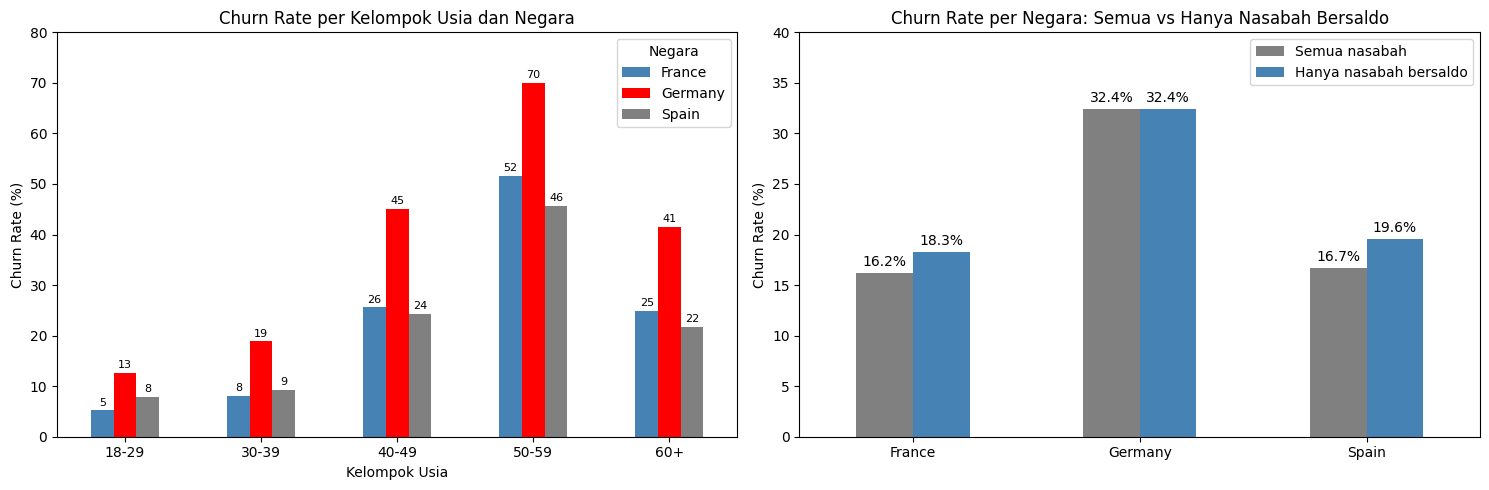

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

usia_negara.plot(kind="bar", ax=ax[0], color=["steelblue", "red", "gray"], rot=0)
for wadah in ax[0].containers:
    ax[0].bar_label(wadah, fmt="%.0f", padding=2, fontsize=8)
ax[0].set_title("Churn Rate per Kelompok Usia dan Negara")
ax[0].set_xlabel("Kelompok Usia")
ax[0].set_ylabel("Churn Rate (%)")
ax[0].set_ylim(0, 80)
ax[0].legend(title="Negara")

bandingkan = pd.DataFrame({
    "Semua nasabah": negara["Churn_Rate"],
    "Hanya nasabah bersaldo": saldo_pos["Churn_Rate"]
})
bandingkan.plot(kind="bar", ax=ax[1], color=["gray", "steelblue"], rot=0)
for wadah in ax[1].containers:
    ax[1].bar_label(wadah, fmt="%.1f%%", padding=3)
ax[1].set_title("Churn Rate per Negara: Semua vs Hanya Nasabah Bersaldo")
ax[1].set_xlabel("")
ax[1].set_ylabel("Churn Rate (%)")
ax[1].set_ylim(0, 40)
ax[1].legend()

plt.tight_layout()
plt.show()

**Temuan:** Germany berada paling atas di semua kelompok usia, dengan
selisih terbesar pada usia 40-49 (45,1% vs sekitar 25%) dan 50-59
(70,0% vs 46-52%). Membandingkan hanya nasabah bersaldo memang
mengecilkan jarak (France naik ke 18,3% dan Spain ke 19,6%), tetapi
Germany tetap hampir dua kali lipat. Tingginya churn Germany belum bisa
dijelaskan oleh data yang tersedia dan perlu diselidiki dari sisi lain,
misalnya persaingan, harga, atau layanan di pasar tersebut.

## 9. Kesimpulan dan Rekomendasi

**Kesimpulan:**
1. Dari 10.000 nasabah, 2.038 churn (20,38%). Risiko tertinggi ada
   pada nasabah usia 50-59 tahun (churn 56,04%), sedangkan kelompok
   40-49 tahun menyumbang porsi churn terbesar (39,6%).
2. Jumlah produk berpola huruf U: nasabah 2 produk paling loyal
   (7,60%), nasabah 1 produk 27,71%, dan nasabah 3-4 produk hampir
   semuanya churn (82,71% dan 100%, total 326 nasabah).
3. Nasabah tidak aktif churn 26,87%, hampir dua kali lipat nasabah aktif
   (14,27%). Nasabah bersaldo tinggi yang tidak aktif (1.569 orang)
   churn 31,23% dan menyumbang 24,0% dari seluruh churn.
4. Germany churn 32,44%, hampir dua kali lipat France (16,17%) dan
   Spain (16,67%). Tingginya tidak dijelaskan oleh usia, keaktifan,
   gender, jumlah produk, atau gaji, karena Germany tertinggi di
   setiap kelompok tersebut.
5. Komplain berkorelasi hampir sempurna dengan churn (0,996) sehingga
   kemungkinan besar dicatat setelah nasabah memutuskan pergi, sedangkan
   skor kepuasan tidak berhubungan dengan churn (korelasi -0,006).

**Rekomendasi:**
1. Prioritaskan program retensi untuk nasabah usia 40-59 tahun,
   terutama 50-59 tahun, misalnya penawaran dan komunikasi yang
   disesuaikan dengan kebutuhan kelompok usia tersebut.
2. Jalankan kampanye pengaktifan kembali untuk nasabah tidak aktif,
   dimulai dari 1.569 nasabah bersaldo tinggi yang tidak aktif karena
   dampak finansialnya paling besar.
3. Dorong nasabah 1 produk ke produk kedua lewat uji coba cross-selling
   skala kecil, karena nasabah 2 produk jauh lebih jarang churn.
4. Tinjau paket dan proses penjualan untuk nasabah 3-4 produk, karena
   hampir semuanya churn, sebelum mendorong lebih dari 2 produk.
5. Selidiki penyebab churn di Germany (persaingan, harga, layanan), dan
   perbaiki pencatatan komplain agar tercatat sebelum nasabah keluar.
   Evaluasi juga cara mengukur skor kepuasan karena belum bisa
   dipakai sebagai sinyal risiko.

**Keterbatasan:**
- Korelasi bukan berarti sebab-akibat. Misalnya, nasabah 2 produk lebih
  loyal belum tentu karena produk keduanya.
- Waktu pencatatan komplain tidak diketahui, sehingga dugaan data
  leakage tidak bisa dipastikan dari data ini.
- Dataset tidak memuat alasan nasabah pergi, tanggal churn, mata uang,
  maupun nilai keuntungan per nasabah.
- Kelompok 3-4 produk kecil (326 nasabah), jadi angkanya perlu dibaca
  hati-hati.
- Analisis ini membandingkan faktor satu per satu dan belum memakai
  model prediktif, sehingga efek gabungan antar faktor belum diukur.
- Dataset berasal dari sumber publik (Kaggle), sehingga proses
  pengumpulan datanya tidak sepenuhnya diketahui.